# Network Science with Python: a practical introduction

This notebook complements the theoretical lecture on **Network Science**.

We will use **NetworkX** to construct, inspect, visualize, and analyse networks.

The notebook starts with very small graphs so that we can verify the results by eye, and finishes with the **Zachary Karate Club** network as a realistic case study.

In [1]:
# Uncomment if needed:
# %pip install -q networkx matplotlib pandas numpy

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NetworkX version:", nx.__version__)

NetworkX version: 3.2.1


## 1. Creating a graph

A graph is usually denoted as $G=(V,E)$, where:

- V is the set of **nodes**;
- E is the set of **edges**.

In [2]:
G = nx.Graph()

G.add_nodes_from(["Alice", "Bob", "Carol", "David", "Emma", "Frank"])

G.add_edges_from([
    ("Alice", "Bob"),
    ("Alice", "Carol"),
    ("Bob", "Carol"),
    ("Carol", "David"),
    ("David", "Emma"),
    ("Emma", "Frank"),
    ("David", "Frank"),
])

print("Nodes:", list(G.nodes()))
print("Edges:", list(G.edges()))

Nodes: ['Alice', 'Bob', 'Carol', 'David', 'Emma', 'Frank']
Edges: [('Alice', 'Bob'), ('Alice', 'Carol'), ('Bob', 'Carol'), ('Carol', 'David'), ('David', 'Emma'), ('David', 'Frank'), ('Emma', 'Frank')]


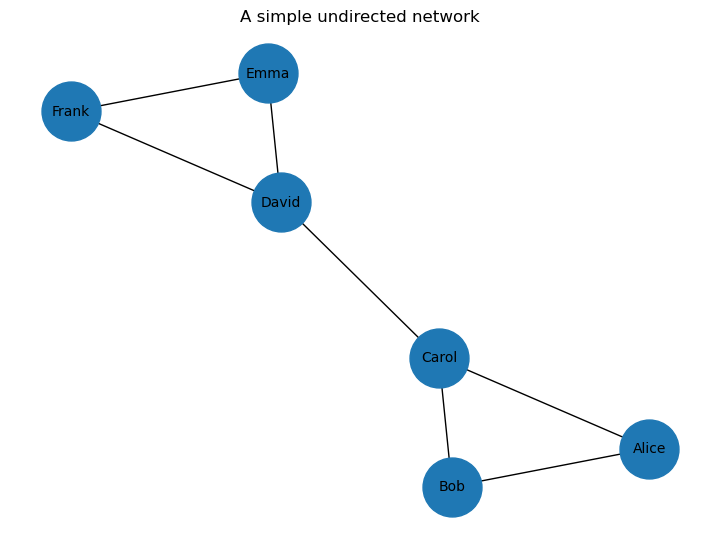

In [3]:
plt.figure(figsize=(7, 5))
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1800,
    font_size=10,
)
plt.title("A simple undirected network")
plt.show()

### Basic graph information

In [4]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

print("Is directed?", G.is_directed())
print("Is a multigraph?", G.is_multigraph())

Number of nodes: 6
Number of edges: 7
Is directed? False
Is a multigraph? False


## 2. Undirected vs. directed graphs

In an **undirected graph**, an edge between \(A\) and \(B\) has no orientation.

Examples:

- friendship;
- co-authorship;
- physical connections.

In a **directed graph**, edges have a direction.

Examples:

- Twitter/X follows;
- citations;
- hyperlinks;
- money transfers.

In [5]:
DG = nx.DiGraph()

DG.add_edges_from([
    ("Alice", "Bob"),
    ("Bob", "Carol"),
    ("Carol", "Alice"),
    ("Carol", "David"),
    ("David", "Bob"),
])

print("Directed?", DG.is_directed())
print("Edges:", list(DG.edges()))

Directed? True
Edges: [('Alice', 'Bob'), ('Bob', 'Carol'), ('Carol', 'Alice'), ('Carol', 'David'), ('David', 'Bob')]


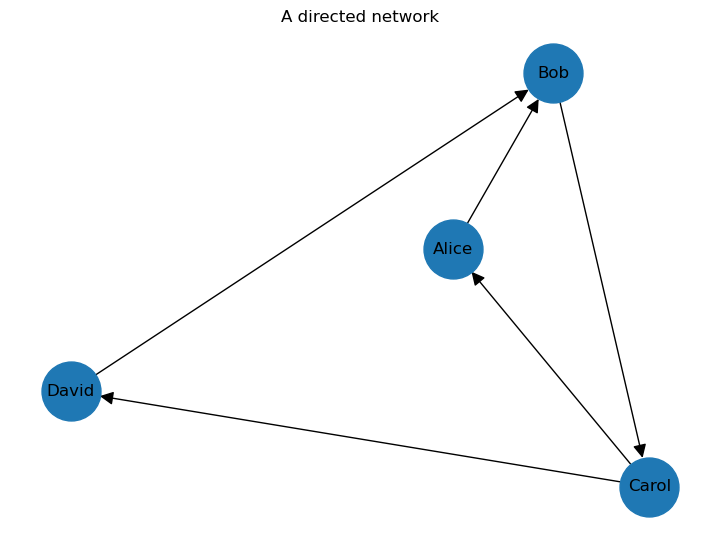

In [6]:
plt.figure(figsize=(7, 5))
pos_dg = nx.spring_layout(DG, seed=42)
nx.draw(
    DG,
    pos_dg,
    with_labels=True,
    node_size=1800,
    arrows=True,
    arrowsize=20,
)
plt.title("A directed network")
plt.show()

For directed networks we distinguish:

- **in-degree**: number of incoming edges;
- **out-degree**: number of outgoing edges.

In [7]:
for node in DG.nodes():
    print(
        f"{node:6s} | "
        f"in-degree = {DG.in_degree(node)} | "
        f"out-degree = {DG.out_degree(node)}"
    )

Alice  | in-degree = 1 | out-degree = 1
Bob    | in-degree = 2 | out-degree = 1
Carol  | in-degree = 1 | out-degree = 2
David  | in-degree = 1 | out-degree = 1


## 3. Unweighted vs. weighted graphs

An unweighted edge only says whether a relationship exists.

A **weighted edge** also stores the strength, frequency, cost, distance, or another numerical quantity associated with the relationship.

In [8]:
WG = nx.Graph()

WG.add_weighted_edges_from([
    ("Alice", "Bob", 5),
    ("Alice", "Carol", 2),
    ("Bob", "Carol", 4),
    ("Carol", "David", 1),
])

for u, v, data in WG.edges(data=True):
    print(f"{u} -- {v}: weight = {data['weight']}")

Alice -- Bob: weight = 5
Alice -- Carol: weight = 2
Bob -- Carol: weight = 4
Carol -- David: weight = 1


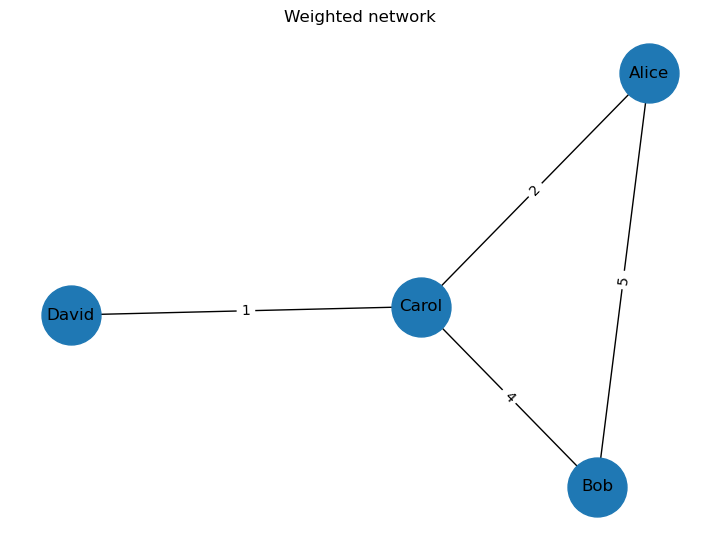

In [9]:
plt.figure(figsize=(7, 5))
pos_wg = nx.spring_layout(WG, seed=42)

nx.draw(
    WG,
    pos_wg,
    with_labels=True,
    node_size=1800,
)

edge_labels = nx.get_edge_attributes(WG, "weight")
nx.draw_networkx_edge_labels(WG, pos_wg, edge_labels=edge_labels)

plt.title("Weighted network")
plt.show()

### Weighted degree

For an unweighted graph, degree counts incident edges.

For a weighted graph, the **weighted degree** (often called *strength*) is the sum of the incident edge weights.

In [10]:
for node in WG.nodes():
    degree = WG.degree(node)
    strength = WG.degree(node, weight="weight")
    print(f"{node:6s} | degree = {degree} | strength = {strength}")

Alice  | degree = 2 | strength = 7
Bob    | degree = 2 | strength = 9
Carol  | degree = 3 | strength = 7
David  | degree = 1 | strength = 1


## 4. Number of nodes, number of edges, degree, and average degree

For an undirected graph,


$\langle k \rangle = \frac{2m}{n}$

where $n$ is the number of nodes and $m$ the number of edges.

In [11]:
n = G.number_of_nodes()
m = G.number_of_edges()

degrees = dict(G.degree())
average_degree = sum(degrees.values()) / n

print("n =", n)
print("m =", m)
print("Degrees:", degrees)
print("Average degree:", average_degree)

# Check using 2m/n
print("2m/n:", 2 * m / n)

n = 6
m = 7
Degrees: {'Alice': 2, 'Bob': 2, 'Carol': 3, 'David': 3, 'Emma': 2, 'Frank': 2}
Average degree: 2.3333333333333335
2m/n: 2.3333333333333335


The equality above follows from $\sum_i k_i = 2m$, because every undirected edge contributes 1 to the degree of each of its two endpoints.

In [12]:
print("Sum of all degrees:", sum(dict(G.degree()).values()))
print("2 × number of edges:", 2 * G.number_of_edges())

Sum of all degrees: 14
2 × number of edges: 14


## 5. Density

Density measures how many of the possible edges actually exist.

For a simple undirected graph:

$D = \frac{2m}{n(n-1)}$

A complete graph has density 1.

In [13]:
density = nx.density(G)

print("Density:", density)

Density: 0.4666666666666667


In [14]:
complete = nx.complete_graph(6)

print("Density of G:", nx.density(G))
print("Density of K6:", nx.density(complete))

Density of G: 0.4666666666666667
Density of K6: 1.0


## 6. Degree distribution

The degree distribution tells us how common each degree value is.

We can first inspect the degree sequence.

In [15]:
degree_sequence = [degree for _, degree in G.degree()]

print("Degree sequence:", degree_sequence)

values, counts = np.unique(degree_sequence, return_counts=True)

degree_distribution = pd.DataFrame({
    "degree": values,
    "count": counts,
    "probability": counts / len(degree_sequence)
})

degree_distribution

Degree sequence: [2, 2, 3, 3, 2, 2]


,degree,count,probability
0,2,4,0.666667
1,3,2,0.333333


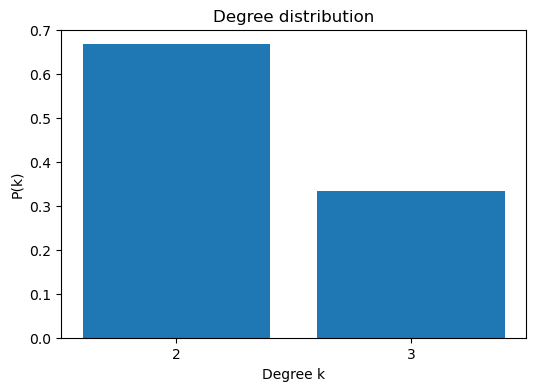

In [16]:
plt.figure(figsize=(6, 4))
plt.bar(
    degree_distribution["degree"],
    degree_distribution["probability"]
)
plt.xlabel("Degree k")
plt.ylabel("P(k)")
plt.title("Degree distribution")
plt.xticks(degree_distribution["degree"])
plt.show()

For larger networks it is common to inspect the degree distribution on logarithmic axes, especially when studying heavy-tailed distributions.

Be careful: a straight-looking line on a log-log plot is **not sufficient evidence** that a network follows a power law.

## 7. Adjacency matrix

For an unweighted network, the adjacency matrix \(A\) contains

$
A_{ij} =
\begin{cases}
1 & \text{if nodes } i \text{ and } j \text{ are connected}\\
0 & \text{otherwise}
\end{cases}
$

For an undirected network, the adjacency matrix is symmetric.

In [17]:
node_order = list(G.nodes())

A = nx.to_numpy_array(G, nodelist=node_order, dtype=int)

adjacency_df = pd.DataFrame(
    A,
    index=node_order,
    columns=node_order
)

adjacency_df

,Alice,Bob,Carol,David,Emma,Frank
Alice,0,1,1,0,0,0
Bob,1,0,1,0,0,0
Carol,1,1,0,1,0,0
David,0,0,1,0,1,1
Emma,0,0,0,1,0,1
Frank,0,0,0,1,1,0


In [18]:
print("Is the adjacency matrix symmetric?")
print(np.array_equal(A, A.T))

Is the adjacency matrix symmetric?
True


For a directed graph, the matrix is generally not symmetric.

In [19]:
directed_nodes = list(DG.nodes())

A_directed = nx.to_numpy_array(
    DG,
    nodelist=directed_nodes,
    dtype=int
)

pd.DataFrame(
    A_directed,
    index=directed_nodes,
    columns=directed_nodes
)

,Alice,Bob,Carol,David
Alice,0,1,0,0
Bob,0,0,1,0
Carol,1,0,0,1
David,0,1,0,0


In [20]:
print("Symmetric?", np.array_equal(A_directed, A_directed.T))

Symmetric? False


## 8. Self-loops

A **self-loop** is an edge that connects a node to itself.

NetworkX allows self-loops.

In [21]:
G_loop = nx.Graph()

G_loop.add_edges_from([
    ("A", "B"),
    ("B", "C"),
    ("C", "C"),
])

print("Edges:", list(G_loop.edges()))
print("Self-loops:", list(nx.selfloop_edges(G_loop)))
print("Number of self-loops:", nx.number_of_selfloops(G_loop))

Edges: [('A', 'B'), ('B', 'C'), ('C', 'C')]
Self-loops: [('C', 'C')]
Number of self-loops: 1


In [22]:
print("Degree of C:", G_loop.degree("C"))

Degree of C: 3


Notice that in an undirected graph a self-loop contributes **2** to the degree of its node.

## 9. Paths, shortest paths, and diameter

A **path** is a sequence of adjacent nodes.

The shortest-path distance $d(i,j)$ is the minimum number of edges required to travel from node $i$ to node $j$ in an unweighted network.

In [23]:
source = "Alice"
target = "Frank"

shortest_path = nx.shortest_path(G, source=source, target=target)
distance = nx.shortest_path_length(G, source=source, target=target)

print("Shortest path:", shortest_path)
print("Distance:", distance)

Shortest path: ['Alice', 'Carol', 'David', 'Frank']
Distance: 3


The **diameter** is the largest shortest-path distance between any pair of nodes:

$
D = \max_{i,j} d(i,j)
$

The graph must be connected for the standard definition used by `nx.diameter`.

In [24]:
print("Connected?", nx.is_connected(G))
print("Diameter:", nx.diameter(G))

Connected? True
Diameter: 3


In [25]:
lengths = dict(nx.all_pairs_shortest_path_length(G))

distance_matrix = pd.DataFrame(lengths).T
distance_matrix

,Alice,Bob,Carol,David,Emma,Frank
Alice,0,1,1,2,3,3
Bob,1,0,1,2,3,3
Carol,1,1,0,1,2,2
David,2,2,1,0,1,1
Emma,3,3,2,1,0,1
Frank,3,3,2,1,1,0


### Disconnected networks

A disconnected network does not have a finite path between every pair of nodes, so `nx.diameter` cannot be applied directly to the entire graph.

A common choice is to calculate the diameter of the **largest connected component**.

In [26]:
G_disconnected = nx.Graph([
    ("A", "B"),
    ("B", "C"),
    ("D", "E"),
])

print("Connected?", nx.is_connected(G_disconnected))

largest_component_nodes = max(
    nx.connected_components(G_disconnected),
    key=len
)

largest_component = G_disconnected.subgraph(
    largest_component_nodes
).copy()

print("Largest connected component:", largest_component_nodes)
print("Diameter of largest component:", nx.diameter(largest_component))

Connected? False
Largest connected component: {'C', 'A', 'B'}
Diameter of largest component: 2


## 10. Assortativity

Degree assortativity measures whether nodes tend to connect to nodes with similar degree.

Interpretation:

- $r > 0$: assortative mixing — high-degree nodes tend to connect to high-degree nodes;
- $r < 0$: disassortative mixing — high-degree nodes tend to connect to low-degree nodes;
- $r \approx 0$: little degree correlation.

In [27]:
r = nx.degree_assortativity_coefficient(G)

print("Degree assortativity:", r)

Degree assortativity: -0.16666666666666508


Let us compare two artificial examples.

In [28]:
# A network containing dense groups connected through a bridge
G_assortative = nx.Graph()

G_assortative.add_edges_from([
    ("A", "B"), ("A", "C"), ("B", "C"),
    ("D", "E"), ("D", "F"), ("E", "F"),
    ("C", "D")
])

# A star is strongly hub-and-spoke
G_star = nx.star_graph(8)

print(
    "Example 1 assortativity:",
    nx.degree_assortativity_coefficient(G_assortative)
)

print(
    "Star assortativity:",
    nx.degree_assortativity_coefficient(G_star)
)

Example 1 assortativity: -0.16666666666666508
Star assortativity: -1.0


## 11. Local clustering coefficient

The local clustering coefficient of node \(i\) measures how connected its neighbours are to one another.

For an undirected unweighted graph:

$
C_i =
\frac{2L_i}{k_i(k_i-1)}
$

where:

- $k_i$ is the degree of node $i$;
- $L_i$ is the number of links among the neighbours of $i$.

A value close to 1 means that the neighbours of a node are highly interconnected.

In [29]:
local_clustering = nx.clustering(G)

for node, value in local_clustering.items():
    print(f"{node:6s}: {value:.3f}")

Alice : 1.000
Bob   : 1.000
Carol : 0.333
David : 0.333
Emma  : 1.000
Frank : 1.000


We can inspect one node explicitly.

In [30]:
node = "Alice"

neighbors = list(G.neighbors(node))

print("Node:", node)
print("Neighbors:", neighbors)
print("Degree:", G.degree(node))
print("Local clustering:", nx.clustering(G, node))

Node: Alice
Neighbors: ['Bob', 'Carol']
Degree: 2
Local clustering: 1.0


## 12. Global clustering

### Average clustering coefficient

$
\bar C = \frac{1}{n}\sum_i C_i
$

In [31]:
print("Average clustering:", nx.average_clustering(G))

Average clustering: 0.7777777777777778


## 13. Degree centrality

Degree centrality is the normalized degree of a node.

For a simple undirected graph with $n$ nodes:

$
C_D(i)=\frac{k_i}{n-1}
$

A node has high degree centrality when it has many direct connections.

In [32]:
degree_centrality = nx.degree_centrality(G)

degree_table = pd.DataFrame({
    "degree": dict(G.degree()),
    "degree_centrality": degree_centrality
}).sort_values("degree_centrality", ascending=False)

degree_table

,degree,degree_centrality
Carol,3,0.6
David,3,0.6
Alice,2,0.4
Bob,2,0.4
Emma,2,0.4
Frank,2,0.4


## 14. Betweenness centrality

Betweenness centrality measures how often a node lies on shortest paths between other nodes.

Conceptually,

$
C_B(v)
=
\sum_{s \ne v \ne t}
\frac{\sigma_{st}(v)}{\sigma_{st}}
$

where:

- $\sigma_{st}$ is the number of shortest paths between $s$ and $t$;
- $\sigma_{st}(v)$ is the number of those shortest paths passing through $v$.

Nodes with high betweenness can act as **bridges** or **brokers** between different parts of a network.

In [33]:
betweenness = nx.betweenness_centrality(G)

betweenness_table = pd.DataFrame({
    "degree": dict(G.degree()),
    "degree_centrality": nx.degree_centrality(G),
    "betweenness_centrality": betweenness
}).sort_values("betweenness_centrality", ascending=False)

betweenness_table

,degree,degree_centrality,betweenness_centrality
Carol,3,0.6,0.6
David,3,0.6,0.6
Alice,2,0.4,0.0
Bob,2,0.4,0.0
Emma,2,0.4,0.0
Frank,2,0.4,0.0


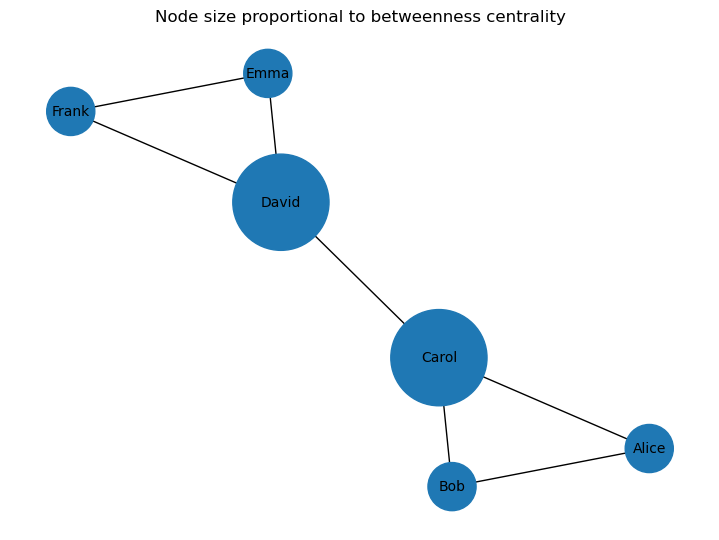

In [34]:
plt.figure(figsize=(7, 5))

node_sizes = [
    1200 + 6000 * betweenness[node]
    for node in G.nodes()
]

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=node_sizes,
    font_size=10,
)

plt.title("Node size proportional to betweenness centrality")
plt.show()

### Degree centrality vs. betweenness centrality

The two concepts answer different questions:

- **degree centrality:** who has many direct connections?
- **betweenness centrality:** who lies on many shortest routes between others?

A node can have modest degree but high betweenness if it connects otherwise separated groups.

## 15. Community detection with Louvain

Louvain searches for a partition of the network that increases **modularity**.

Modularity compares the observed density of edges within communities with the density expected under a degree-preserving null model.

For an undirected network:

$
Q =
\frac{1}{2m}
\sum_{ij}
\left(
A_{ij} - \frac{k_i k_j}{2m}
\right)
\delta(c_i,c_j)
$

A larger $Q$ means that the proposed communities contain more internal connectivity than expected under the null model.

In [35]:
communities = nx.community.louvain_communities(
    G,
    seed=42
)

print("Detected communities:")
for i, community in enumerate(communities):
    print(f"Community {i}: {sorted(community)}")

Detected communities:
Community 0: ['Alice', 'Bob', 'Carol']
Community 1: ['David', 'Emma', 'Frank']


In [36]:
Q = nx.community.modularity(G, communities)

print("Modularity:", Q)

Modularity: 0.35714285714285715


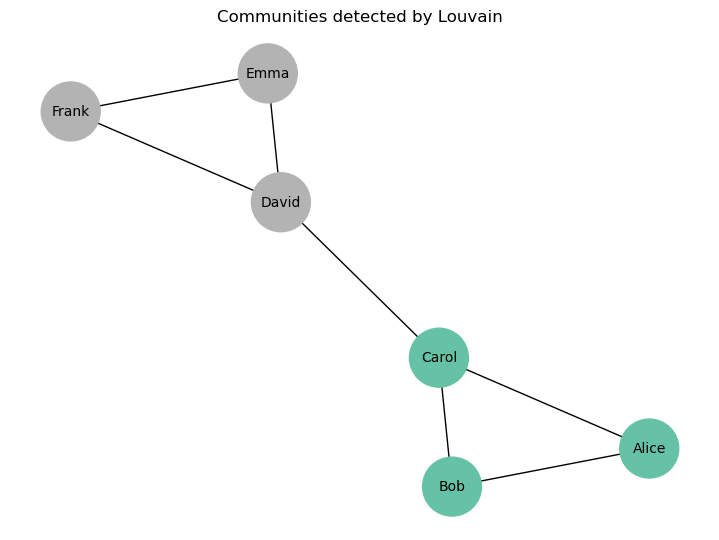

In [37]:
community_id = {}

for i, community in enumerate(communities):
    for node in community:
        community_id[node] = i

node_communities = [
    community_id[node]
    for node in G.nodes()
]

plt.figure(figsize=(7, 5))
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_communities,
    cmap=plt.cm.Set2,
    node_size=1800,
    font_size=10,
)
plt.title("Communities detected by Louvain")
plt.show()

### Important note about Louvain

Louvain is a **heuristic** algorithm.

Its result can depend on node ordering and randomization, so setting a seed is useful for reproducible examples.

The `resolution` parameter also controls the scale of the communities:

- lower resolution tends to favour larger communities;
- higher resolution tends to favour smaller communities.

In [38]:
for resolution in [0.5, 1.0, 2.0]:
    communities_r = nx.community.louvain_communities(
        G,
        resolution=resolution,
        seed=42
    )

    q_r = nx.community.modularity(
        G,
        communities_r,
        resolution=resolution
    )

    print(
        f"resolution={resolution:3.1f} | "
        f"communities={len(communities_r)} | "
        f"modularity={q_r:.3f}"
    )

resolution=0.5 | communities=2 | modularity=0.607
resolution=1.0 | communities=2 | modularity=0.357
resolution=2.0 | communities=2 | modularity=-0.143


## 16. A more realistic example: Zachary's Karate Club

The **Karate Club graph** is a classic social network included directly in NetworkX.

Nodes represent members of a university karate club and edges represent observed social interactions between members.

In [39]:
K = nx.karate_club_graph()

print("Nodes:", K.number_of_nodes())
print("Edges:", K.number_of_edges())
print("Directed?", K.is_directed())
print("Density:", nx.density(K))
print("Average degree:", np.mean([d for _, d in K.degree()]))
print("Connected?", nx.is_connected(K))
print("Diameter:", nx.diameter(K))
print(
    "Degree assortativity:",
    nx.degree_assortativity_coefficient(K)
)
print(
    "Average clustering:",
    nx.average_clustering(K)
)

Nodes: 34
Edges: 78
Directed? False
Density: 0.13903743315508021
Average degree: 4.588235294117647
Connected? True
Diameter: 5
Degree assortativity: -0.47561309768461413
Average clustering: 0.5706384782076823


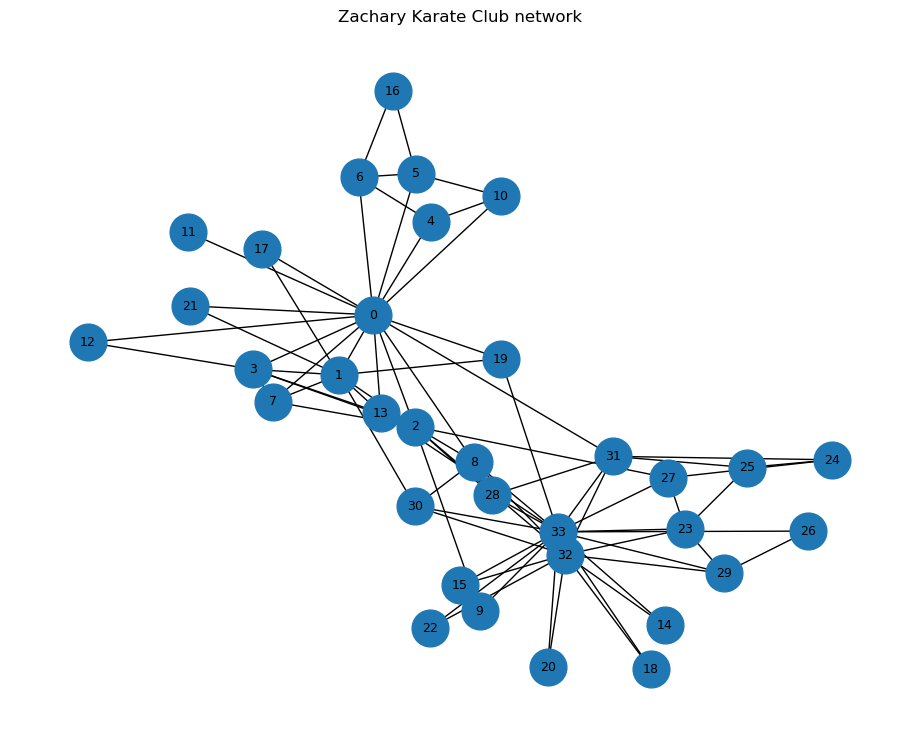

In [40]:
plt.figure(figsize=(9, 7))

pos_k = nx.spring_layout(K, seed=42)

nx.draw(
    K,
    pos_k,
    with_labels=True,
    node_size=700,
    font_size=9,
)

plt.title("Zachary Karate Club network")
plt.show()

### Degree distribution of the Karate Club network

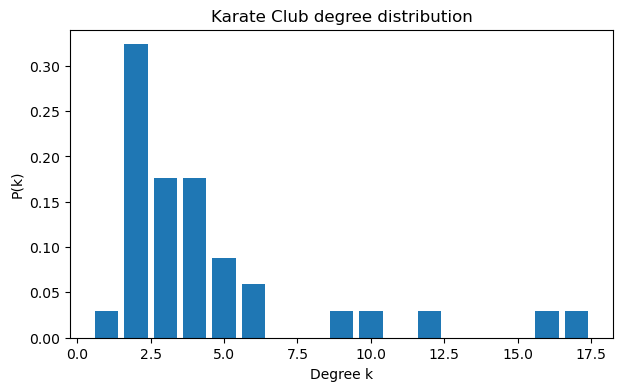

In [41]:
karate_degrees = [d for _, d in K.degree()]

degree_values, degree_counts = np.unique(
    karate_degrees,
    return_counts=True
)

plt.figure(figsize=(7, 4))
plt.bar(degree_values, degree_counts / K.number_of_nodes())
plt.xlabel("Degree k")
plt.ylabel("P(k)")
plt.title("Karate Club degree distribution")
plt.show()

### Centrality in the Karate Club network

In [42]:
karate_degree_centrality = nx.degree_centrality(K)
karate_betweenness = nx.betweenness_centrality(K)

centrality_df = pd.DataFrame({
    "degree": dict(K.degree()),
    "degree_centrality": karate_degree_centrality,
    "betweenness_centrality": karate_betweenness
})

centrality_df.sort_values(
    "betweenness_centrality",
    ascending=False
).head(10)

,degree,degree_centrality,betweenness_centrality
0,16,0.484848,0.437635
33,17,0.515152,0.304075
32,12,0.363636,0.145247
2,10,0.303030,0.143657
31,6,0.181818,0.138276
8,5,0.151515,0.055927
1,9,0.272727,0.053937
13,5,0.151515,0.045863
19,3,0.090909,0.032475
5,4,0.121212,0.029987


This table lets us compare nodes that are locally popular with nodes that are structurally important as bridges.

### Louvain communities in the Karate Club network

In [43]:
karate_communities = nx.community.louvain_communities(
    K,
    seed=42
)

print("Number of communities:", len(karate_communities))

for i, community in enumerate(karate_communities):
    print(
        f"Community {i}: "
        f"{sorted(community)}"
    )

print(
    "Modularity:",
    nx.community.modularity(
        K,
        karate_communities
    )
)

Number of communities: 4
Community 0: [1, 2, 3, 7, 12, 13]
Community 1: [0, 4, 5, 6, 10, 11, 16, 17, 19, 21]
Community 2: [24, 25, 28, 31]
Community 3: [8, 9, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33]
Modularity: 0.4266224396094526


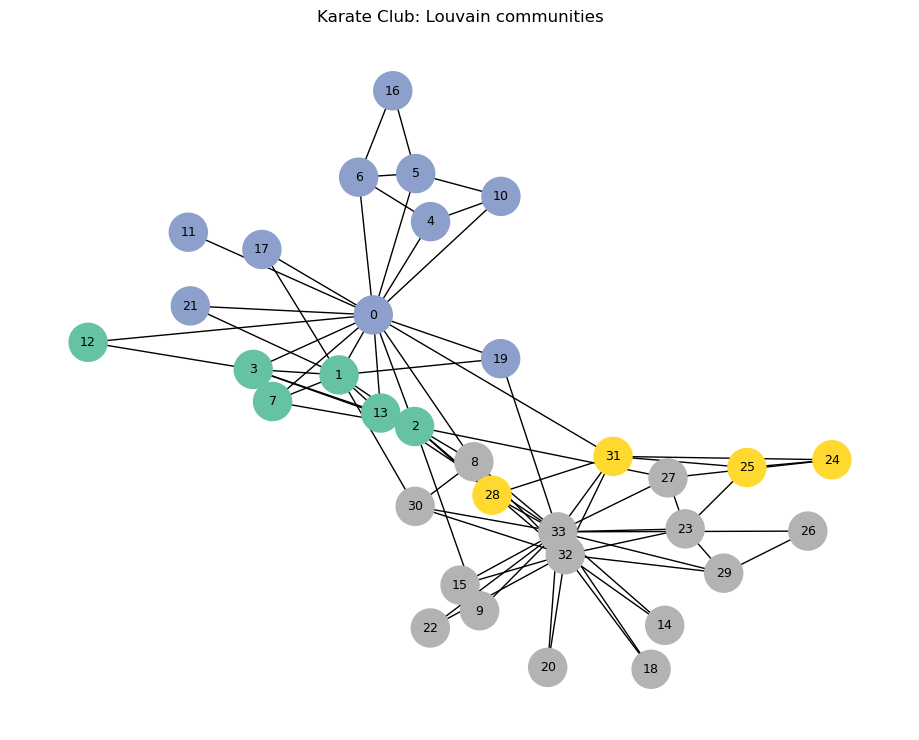

In [44]:
karate_community_id = {}

for i, community in enumerate(karate_communities):
    for node in community:
        karate_community_id[node] = i

colors = [
    karate_community_id[node]
    for node in K.nodes()
]

plt.figure(figsize=(9, 7))

nx.draw(
    K,
    pos_k,
    with_labels=True,
    node_color=colors,
    cmap=plt.cm.Set2,
    node_size=750,
    font_size=9,
)

plt.title("Karate Club: Louvain communities")
plt.show()

## 17. Putting the main network statistics together

For convenience, we can define a small function that returns the main descriptive statistics of an undirected graph.

In [45]:
def network_summary(G):
    summary = {
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "directed": G.is_directed(),
        "density": nx.density(G),
        "average_degree": (
            sum(dict(G.degree()).values()) / G.number_of_nodes()
            if G.number_of_nodes() > 0 else np.nan
        ),
        "average_clustering": (
            nx.average_clustering(G)
            if not G.is_directed() else np.nan
        ),
        "degree_assortativity": (
            nx.degree_assortativity_coefficient(G)
            if G.number_of_edges() > 0 else np.nan
        ),
    }

    if not G.is_directed() and nx.is_connected(G):
        summary["diameter"] = nx.diameter(G)
    else:
        summary["diameter"] = np.nan

    return pd.Series(summary)

In [46]:
summary_table = pd.DataFrame({
    "Toy network": network_summary(G),
    "Karate Club": network_summary(K),
})

summary_table

,Toy network,Karate Club
nodes,6,34
edges,7,78
directed,False,False
density,0.466667,0.139037
average_degree,2.333333,4.588235
average_clustering,0.777778,0.570638
degree_assortativity,-0.166667,-0.475613
diameter,3,5


## 18. Weighted shortest paths
The meaning of an edge weight depends on the application.

Suppose an edge weight represents **distance or cost**. Then a larger weight means it is harder or longer to traverse the edge, and NetworkX can directly use it as a shortest-path distance.

In [47]:
distance_graph = nx.Graph()

distance_graph.add_weighted_edges_from([
    ("A", "B", 2),
    ("B", "C", 2),
    ("A", "C", 10),
])

print(
    nx.shortest_path(
        distance_graph,
        "A",
        "C",
        weight="weight"
    )
)

print(
    nx.shortest_path_length(
        distance_graph,
        "A",
        "C",
        weight="weight"
    )
)

['A', 'B', 'C']
4


If instead a weight represents **tie strength**, similarity, or number of interactions, a larger value means a *stronger* relationship rather than a longer distance.

In that case it is usually inappropriate to directly use the strength as a distance. One possible transformation is

$
d_{ij} = \frac{1}{w_{ij}}
$

when all weights are positive.

In [48]:
strength_graph = nx.Graph()

strength_graph.add_weighted_edges_from([
    ("A", "B", 10),
    ("B", "C", 10),
    ("A", "C", 1),
])

for u, v, data in strength_graph.edges(data=True):
    data["distance"] = 1 / data["weight"]

print(
    "Shortest path using strength-derived distances:",
    nx.shortest_path(
        strength_graph,
        "A",
        "C",
        weight="distance"
    )
)

Shortest path using strength-derived distances: ['A', 'B', 'C']


This distinction is particularly important when computing:

- weighted shortest paths;
- weighted betweenness centrality;
- closeness measures.

NetworkX interprets the `weight` argument of shortest-path based centrality measures as a **distance/cost**.

## 19. CDlib

If you later want to compare many community-detection algorithms under a common interface, the `cdlib` package can be convenient.

pip install -q cdlib


In [49]:
from cdlib import algorithms

communities_cdlib = algorithms.louvain(K)
communities_cdlib.communities

Note: to be able to use all crisp methods, you need to install some additional packages:  {'leidenalg', 'graph_tool', 'bayanpy'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'pyclustering', 'ASLPAw'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'leidenalg'}


[[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33],
 [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21],
 [23, 24, 25, 27, 28, 31],
 [4, 5, 6, 10, 16]]